<a href="https://colab.research.google.com/github/saadkhokar-creator/231A019-NLP-Experiments/blob/main/nlpassaignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [feedparser]


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


NEWS ARTICLES
                                               Title  \
0  Defenders of Digital Bharat: Navigating cybers...   
1  India Weighs US-Style Frontier AI Safeguards A...   
2  TN to not merely follow technology but create ...   
3  Trump says he will ban the term 'artificial in...   
4  Indian AI companies showcase homegrown technol...   
5  Artificial intelligence is transforming indust...   
6  India's daily multimodal AI use to nearly doub...   
7  AI not yet hurting Indian IT firms, GCCs bigge...   
8  A desi AI kill chain? Indian military steps to...   
9  IIT Kharagpur Announces India's First School f...   

                                                Link  \
0  https://news.google.com/rss/articles/CBMi6gFBV...   
1  https://news.google.com/rss/articles/CBMiyAFBV...   
2  https://news.google.com/rss/articles/CBMi0gFBV...   
3  https://news.google.com/rss/articles/CBMi8wFBV...   
4  https://news.google.com/rss/articles/CBMipgFBV...   
5  https://news.google.com/rss/ar

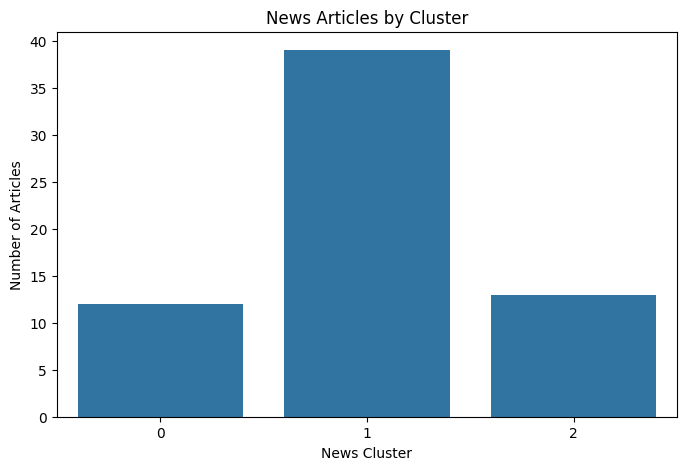

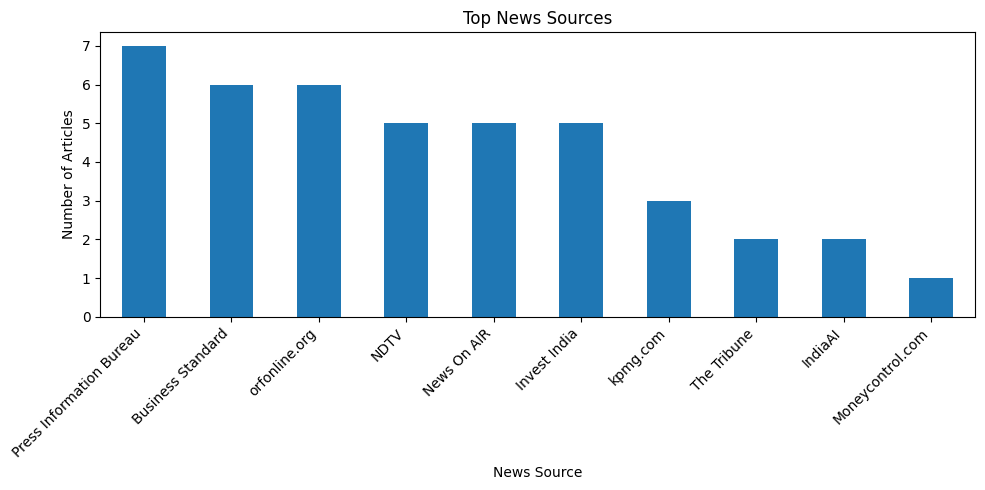


SIMILAR NEWS ARTICLES

Article 1: Trump says he will ban the term 'artificial intelligence', wants it called 'super intelligence' - The Times of India
Article 2: Trump says US to ban artificial intelligence term, pushes super intelligence - The Tribune
Similarity: 0.61

Article 1: IIT Kharagpur Announces India's First School for Physical AI - Check Courses, Curriculum Details - Telegraph India
Article 2: IIT Kharagpur Plans India's First Physical Artificial Intelligence School - NDTV
Similarity: 0.53

Article 1: Artificial Intelligence and India’s National Security - orfonline.org
Article 2: Artificial Intelligence and India’s One Health Moment - orfonline.org
Similarity: 0.34

Article 1: Artificial Intelligence and India’s National Security - orfonline.org
Article 2: India’s national security at a crossroads: Role of artificial intelligence and emerging technologies - kpmg.com
Similarity: 0.50

Article 1: Artificial Intelligence and India’s National Security - orfonline.org
Article 2

In [1]:
# Install required libraries
!pip install feedparser pandas nltk scikit-learn matplotlib seaborn

# Import libraries
import feedparser
import pandas as pd
import nltk
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')
from nltk.corpus import stopwords

# Define news sources using Google News RSS
query = "India Artificial Intelligence"
url = f"https://news.google.com/rss/search?q={query.replace(' ', '+')}&hl=en-IN&gl=IN&ceid=IN:en"

feed = feedparser.parse(url)

# Extract news articles
articles = []

for entry in feed.entries:
    articles.append({
        'Title': entry.get('title', ''),
        'Link': entry.get('link', ''),
        'Published': entry.get('published', ''),
        'Source': entry.get('source', {}).get('title', 'Unknown')
    })

df = pd.DataFrame(articles)

# Display collected news
print("NEWS ARTICLES")
print(df.head(10))

print("\nTotal articles collected:", len(df))

if df.empty:
    print("No articles found. Try another search query.")
else:
    # Text preprocessing
    stop_words = set(stopwords.words('english'))

    def preprocess(text):
        text = text.lower()
        text = re.sub(r'[^a-zA-Z\s]', '', text)
        words = text.split()
        words = [word for word in words if word not in stop_words]
        return ' '.join(words)

    df['Processed_Title'] = df['Title'].apply(preprocess)

    # Remove duplicate headlines
    df = df.drop_duplicates(subset=['Processed_Title']).reset_index(drop=True)

    print("\nPREPROCESSED NEWS")
    print(df[['Title', 'Processed_Title']].head(10))

    # TF-IDF feature extraction
    if len(df) >= 2:
        vectorizer = TfidfVectorizer()
        X = vectorizer.fit_transform(df['Processed_Title'])

        # Determine number of clusters
        k = min(3, len(df))

        # News categorization using K-Means
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        df['Cluster'] = model.fit_predict(X)

        print("\nNEWS CATEGORIZATION")
        print(df[['Title', 'Cluster']].sort_values('Cluster'))

        # Calculate similarity between headlines
        similarity_matrix = cosine_similarity(X)

        print("\nSIMILARITY MATRIX")
        print(pd.DataFrame(
            similarity_matrix,
            index=df['Title'],
            columns=df['Title']
        ).round(2))

        # Plot news clusters
        plt.figure(figsize=(8, 5))
        sns.countplot(data=df, x='Cluster')
        plt.title('News Articles by Cluster')
        plt.xlabel('News Cluster')
        plt.ylabel('Number of Articles')
        plt.show()

        # Plot article sources
        plt.figure(figsize=(10, 5))
        df['Source'].value_counts().head(10).plot(kind='bar')
        plt.title('Top News Sources')
        plt.xlabel('News Source')
        plt.ylabel('Number of Articles')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

        # Display similar news articles
        print("\nSIMILAR NEWS ARTICLES")

        for i in range(len(df)):
            for j in range(i + 1, len(df)):
                if similarity_matrix[i, j] >= 0.3:
                    print(f"\nArticle 1: {df.iloc[i]['Title']}")
                    print(f"Article 2: {df.iloc[j]['Title']}")
                    print(f"Similarity: {similarity_matrix[i, j]:.2f}")

    else:
        print("Not enough unique articles for clustering.")

    # Save results
    df.to_csv('news_aggregation_results.csv', index=False)
    print("\nResults saved to news_aggregation_results.csv")